In [1]:
import pandas as pd

# 41 NSL-KDD features + label + difficulty score
columns = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted", "num_root", "num_file_creations",
    "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login",
    "is_guest_login", "count", "srv_count", "serror_rate", "srv_serror_rate",
    "rerror_rate", "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
    "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate", "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label", "difficulty"
]

train_url = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain+.txt"
test_url  = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTest+.txt"

train_df = pd.read_csv(train_url, names=columns)
test_df  = pd.read_csv(test_url, names=columns)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("\nTop 5 labels in Train:\n", train_df["label"].value_counts().head())

Train shape: (125973, 43)
Test shape: (22544, 43)

Top 5 labels in Train:
 label
normal       67343
neptune      41214
satan         3633
ipsweep       3599
portsweep     2931
Name: count, dtype: int64


In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# 1. Create binary target: 0 = normal, 1 = attack
y_train = (train_df["label"] != "normal").astype(int)
y_test  = (test_df["label"] != "normal").astype(int)

# 2. Drop label and 'difficulty' (difficulty is metadata, not a real network feature)
X_train_raw = train_df.drop(columns=["label", "difficulty"])
X_test_raw  = test_df.drop(columns=["label", "difficulty"])

# 3. Identify categorical vs numeric columns
cat_cols = ["protocol_type", "service", "flag"]
num_cols = [c for c in X_train_raw.columns if c not in cat_cols]

# 4. Fit OneHotEncoder ONLY on training data to prevent data leakage
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", "passthrough", num_cols),
    ],
    verbose_feature_names_out=False
)

X_train = preprocessor.fit_transform(X_train_raw)
X_test  = preprocessor.transform(X_test_raw)
feature_names = preprocessor.get_feature_names_out()

# 5. Sanity checks
print("Processed X_train shape:", X_train.shape)
print("Processed X_test shape: ", X_test.shape)
print("Any NaN in train/test?: ", pd.isna(X_train).any(), "/", pd.isna(X_test).any())
print("\nTrain class balance (0=Normal, 1=Attack):\n", y_train.value_counts(normalize=True).round(3))
print("\nTest class balance (0=Normal, 1=Attack):\n", y_test.value_counts(normalize=True).round(3))

Processed X_train shape: (125973, 122)
Processed X_test shape:  (22544, 122)
Any NaN in train/test?:  False / False

Train class balance (0=Normal, 1=Attack):
 label
0    0.535
1    0.465
Name: proportion, dtype: float64

Test class balance (0=Normal, 1=Attack):
 label
1    0.569
0    0.431
Name: proportion, dtype: float64


In [3]:
import time
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

# 1. Define baselines and Random Forest
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42)
    ),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_features="sqrt",
        oob_score=True,
        n_jobs=-1,
        random_state=42
    )
}

# 2. Train and evaluate each model
results = []
trained_models = {}

for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    far = fp / (fp + tn)  # False Alarm Rate (FPR)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall (DR)": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "FAR (FPR)": far,
        "Train Time (s)": train_time
    })
    trained_models[name] = model

# 3. Display clean comparison table
results_df = pd.DataFrame(results).set_index("Model").round(4)
display(results_df)

# 4. Save Random Forest outputs for Step 4 plots
rf_model = trained_models["Random Forest"]
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]
print(f"\nRandom Forest Out-of-Bag (OOB) Train Accuracy: {rf_model.oob_score_:.4f}")

,Accuracy,Precision,Recall (DR),F1-Score,ROC-AUC,FAR (FPR),Train Time (s)
Model,,,,,,,
Logistic Regression,0.7534,0.9173,0.6229,0.7420,0.7804,0.0742,13.2364
Decision Tree,0.8151,0.9599,0.7047,0.8127,0.8331,0.0389,5.3017
Random Forest,0.7758,0.9689,0.6262,0.7607,0.9619,0.0266,33.4620



Random Forest Out-of-Bag (OOB) Train Accuracy: 0.9990


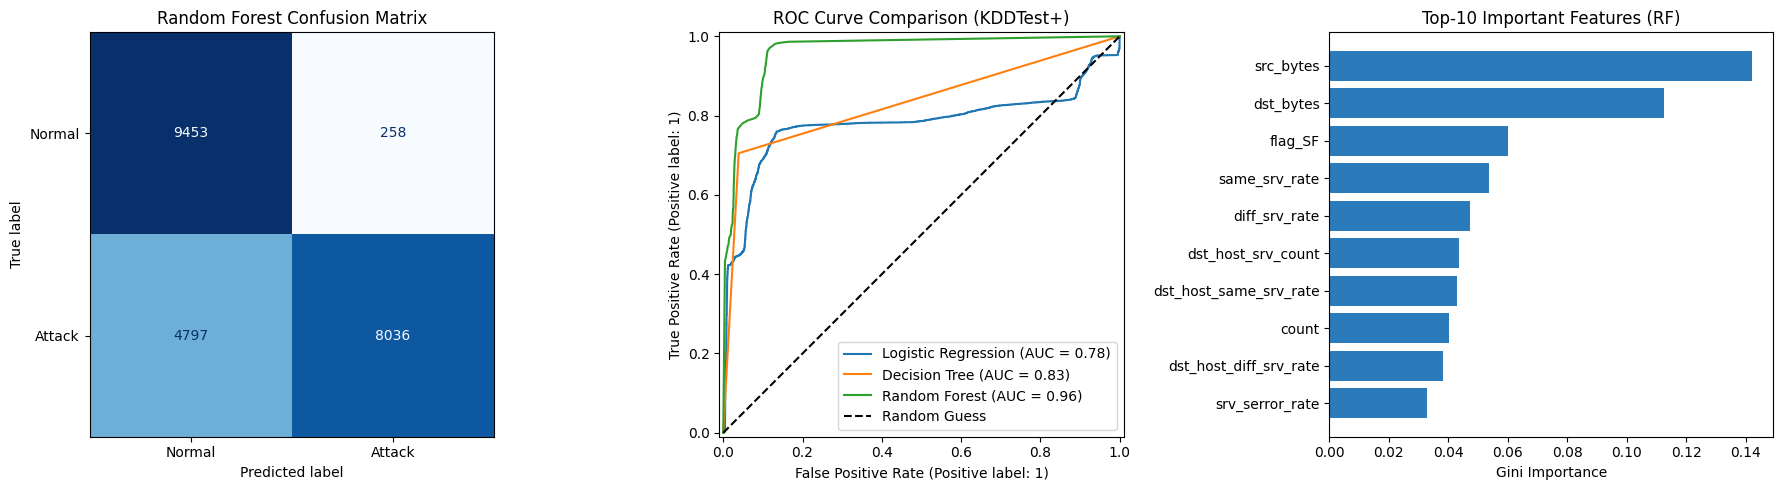

Saved high-res plot to: rf_evaluation_plots.png


In [4]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Confusion Matrix (Random Forest)
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    display_labels=["Normal", "Attack"],
    cmap="Blues",
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Random Forest Confusion Matrix")

# 2. ROC Curve (Compare all 3 models)
for name, model in trained_models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    RocCurveDisplay.from_predictions(y_test, y_prob, name=name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Random Guess")
axes[1].set_title("ROC Curve Comparison (KDDTest+)")
axes[1].legend(loc="lower right")

# 3. Top-10 Feature Importance (Random Forest)
importances = rf_model.feature_importances_
top_idx = np.argsort(importances)[-10:]

axes[2].barh(feature_names[top_idx], importances[top_idx], color="#2b7bba")
axes[2].set_title("Top-10 Important Features (RF)")
axes[2].set_xlabel("Gini Importance")

plt.tight_layout()
plt.savefig("rf_evaluation_plots.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved high-res plot to: rf_evaluation_plots.png")

In [5]:
import pandas as pd

# Identify which attack labels appeared in KDDTrain+
seen_labels = set(train_df["label"].unique())

eval_df = pd.DataFrame({
    "attack_type": test_df["label"].values,
    "y_true": y_test.values,
    "y_pred": y_pred_rf
})

# Keep only actual attacks (y_true == 1)
attacks_only = eval_df[eval_df["y_true"] == 1].copy()
attacks_only["in_train"] = attacks_only["attack_type"].isin(seen_labels)
attacks_only["detected"] = (attacks_only["y_pred"] == 1)

# 1. Detection Rate: Seen vs Unseen Attacks
seen_summary = attacks_only.groupby("in_train").agg(
    total_attacks=("detected", "count"),
    detected=("detected", "sum"),
    missed=("detected", lambda s: (~s).sum()),
    detection_rate=("detected", "mean")
)
seen_summary.index = seen_summary.index.map({
    True: "Seen in Train",
    False: "Unseen in Train (Zero-Day)"
})
print("Random Forest Detection Rate (Seen vs. Unseen Attacks):")
display(seen_summary.round(4))

# 2. Top-10 Most Missed Specific Attack Types
missed_top10 = (
    attacks_only[~attacks_only["detected"]]
    .groupby(["attack_type", "in_train"])
    .size()
    .reset_index(name="missed_count")
    .sort_values("missed_count", ascending=False)
    .head(10)
)
print("\nTop 10 Most Missed Attack Types in KDDTest+:")
display(missed_top10)

Random Forest Detection Rate (Seen vs. Unseen Attacks):


,total_attacks,detected,missed,detection_rate
in_train,,,,
Unseen in Train (Zero-Day),3750,1048,2702,0.2795
Seen in Train,9083,6988,2095,0.7693



Top 10 Most Missed Attack Types in KDDTest+:


,attack_type,in_train,missed_count
4,guess_passwd,True,1231
25,warezmaster,True,793
17,processtable,False,679
10,mscan,False,640
0,apache2,False,380
23,snmpguess,False,331
9,mailbomb,False,293
22,snmpgetattack,False,178
5,httptunnel,False,129
2,buffer_overflow,True,18
